In [2]:
#nombre: Maximiliano Olivero
#Rut: 21664281-3

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed = 1626)

In [3]:
#1)

a_t = np.linspace(0,10,500)

flujo = np.ones(500)

#ruido gaussiano
ruido = rng.normal(loc=0.0, scale=0.002, size= 500)
flujo += ruido

primer_transito = (a_t >= 4.5) & (a_t <= 5.0)
flujo[primer_transito] -= 0.02

segundo_transito = (a_t >= 7) & (a_t <= 7.4)
flujo[segundo_transito] -= 0.015

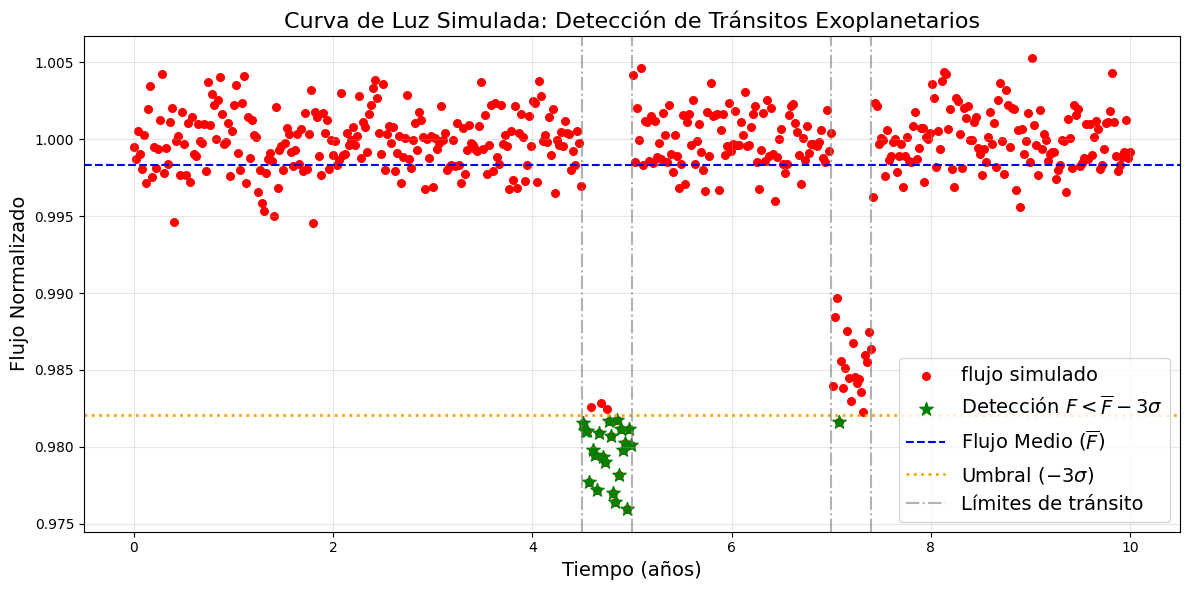

In [15]:
#a)

def curva_luz(a_t,flujo):
  #media y desviacion estandar

  flujo_media = np.mean(flujo)
  flujo_std = np.std(flujo)

  condicion = flujo < (flujo_media - 3 * flujo_std)

  plt.figure(figsize=(12, 6))

  #puntos de la curva de luz
  plt.scatter(a_t, flujo, color='r', marker='o', s=30, label='flujo simulado')

  #condicion
  plt.scatter(a_t[condicion], flujo[condicion], color='green', marker='*', s=100,
                label=r'Detección $F < \overline{F} - 3\sigma$')

  #linea horizontal media
  plt.axhline(flujo_media, color='b', linestyle='--', linewidth=1.5,
                label=r'Flujo Medio ($\overline{F}$)')

  #linea horizontal umbralm de deteccion
  plt.axhline(flujo_media - 3*flujo_std, color='orange', linestyle=':', linewidth=2,
                label=r'Umbral ($-3\sigma$)')

  #lineas verticales
  #primer transito
  plt.axvline(4.5, color='gray', linestyle='-.', alpha=0.6, label='Límites de tránsito')
  plt.axvline(5.0, color='gray', linestyle='-.', alpha=0.6)
  #segundo transito
  plt.axvline(7.0, color='gray', linestyle='-.', alpha=0.6)
  plt.axvline(7.4, color='gray', linestyle='-.', alpha=0.6)

  #etiqueta de tamaño de fuente
  plt.xlabel('Tiempo (años)', fontsize=14)
  plt.ylabel('Flujo Normalizado', fontsize=14)

  #titulo
  plt.title('Curva de Luz Simulada: Detección de Tránsitos Exoplanetarios', fontsize=16)


  #leyenda
  plt.legend(fontsize=14, loc='lower right')

  plt.grid(True, alpha=0.3)
  plt.tight_layout()
  plt.show()

curva_luz(a_t,flujo)